<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>1. Importing Libraries</b>
</div>

In [1]:
import numpy as np
import pandas as pd
import os
import warnings
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from scipy.stats.mstats import winsorize
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler

<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>2. Data Importing</b>
</div>

In [2]:
def load_csv(file_path):
    """Loads a CSV file into a DataFrame"""
    try:
        if not os.path.exists(file_path):
            raise FileNotFoundError(f"Error: File '{file_path}' not found!")

        df = pd.read_csv(file_path)

        print(f"✅ CSV file! Shape: {df.shape}")

        return df
    except FileNotFoundError as fnf_error:
        print(fnf_error)
    except pd.errors.EmptyDataError:
        print("Error: The CSV file is empty!")
    except pd.errors.ParserError:
        print("Error: CSV parsing issue. Check the file format.")
    except Exception as e:
        print(f"Unexpected error: {e}")

    return None  

In [3]:
df = load_csv("/kaggle/input/stroke-risk-prediction-dataset/stroke_risk_dataset.csv")

✅ CSV file! Shape: (70000, 18)


In [4]:
df.head()

,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Age,Stroke Risk (%),At Risk (Binary)
0,0,1,1,1,0,0,0,1,1,1,0,1,1,0,0,54,58.0,1
1,0,0,1,0,0,1,0,0,0,0,1,0,1,1,0,49,40.5,0
2,1,0,0,1,1,1,0,0,1,0,0,0,0,1,0,62,52.0,1
3,1,0,1,1,0,1,1,1,1,1,1,0,0,0,0,48,60.0,1
4,0,0,1,0,0,1,0,1,0,1,1,0,0,1,1,61,56.5,1


In [5]:
df.columns

Index(['Chest Pain', 'Shortness of Breath', 'Irregular Heartbeat',
       'Fatigue & Weakness', 'Dizziness', 'Swelling (Edema)',
       'Pain in Neck/Jaw/Shoulder/Back', 'Excessive Sweating',
       'Persistent Cough', 'Nausea/Vomiting', 'High Blood Pressure',
       'Chest Discomfort (Activity)', 'Cold Hands/Feet', 'Snoring/Sleep Apnea',
       'Anxiety/Feeling of Doom', 'Age', 'Stroke Risk (%)',
       'At Risk (Binary)'],
      dtype='object')

In [6]:
def get_basic_info(df):
    """Get basic information about the dataset"""
    print(f"🔹 Number of Rows: {df.shape[0]}")
    print(f"🔹 Number of Columns: {df.shape[1]}")
    print(f"🔹 Columns: {df.columns.tolist()}")
    print(f"🔹 Column Data Types: {df.dtypes}")
    print(f"🔹 Missing Values: {df.isnull().sum().sum()}")
    print(f"🔹 Missing Values (Per Column) : {df.isnull().sum()}")
    print(f"🔹 Missing Values (Per Column Percentage) : {(df.isnull().mean() * 100)}")
    print(f"🔹 Unique Values: {df.nunique()}")

In [7]:
get_basic_info(df)

🔹 Number of Rows: 70000
🔹 Number of Columns: 18
🔹 Columns: ['Chest Pain', 'Shortness of Breath', 'Irregular Heartbeat', 'Fatigue & Weakness', 'Dizziness', 'Swelling (Edema)', 'Pain in Neck/Jaw/Shoulder/Back', 'Excessive Sweating', 'Persistent Cough', 'Nausea/Vomiting', 'High Blood Pressure', 'Chest Discomfort (Activity)', 'Cold Hands/Feet', 'Snoring/Sleep Apnea', 'Anxiety/Feeling of Doom', 'Age', 'Stroke Risk (%)', 'At Risk (Binary)']
🔹 Column Data Types: Chest Pain                          int64
Shortness of Breath                 int64
Irregular Heartbeat                 int64
Fatigue & Weakness                  int64
Dizziness                           int64
Swelling (Edema)                    int64
Pain in Neck/Jaw/Shoulder/Back      int64
Excessive Sweating                  int64
Persistent Cough                    int64
Nausea/Vomiting                     int64
High Blood Pressure                 int64
Chest Discomfort (Activity)         int64
Cold Hands/Feet                     

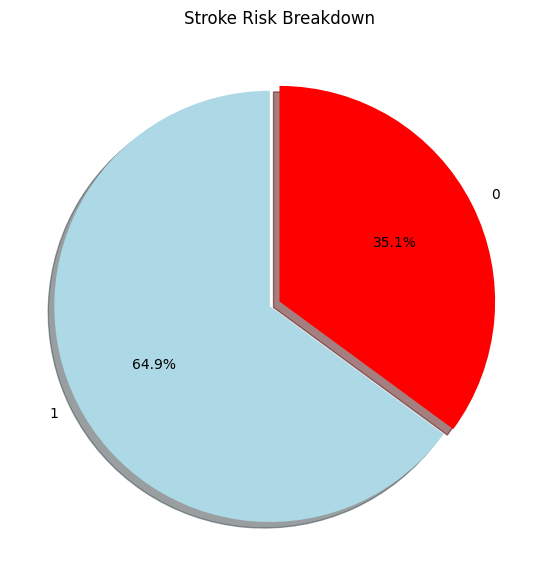

In [8]:
labels = df['At Risk (Binary)'].value_counts(sort=True).index
sizes = df['At Risk (Binary)'].value_counts(sort=True)

colors = ["lightblue", "red"]
explode = (0.05, 0)

plt.figure(figsize=(7, 7))
plt.pie(sizes[:2], explode=explode, labels=labels[:2], colors=colors, autopct='%1.1f%%', shadow=True, startangle=90)

plt.title('Stroke Risk Breakdown')
plt.show()


**Preprocessing Steps**

In [9]:
# Check for class imbalance
df['At Risk (Binary)'].value_counts()/len(df)

At Risk (Binary)
1    0.6492
0    0.3508
Name: count, dtype: float64

In [10]:
# Check for duplicates  --> ~0.015%
print("Duplicates:", df.duplicated().sum()/len(df))
df.drop_duplicates(inplace=True)

Duplicates: 0.014585714285714285


<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>3. Handling Missing Values</b>
</div>

In [11]:
# Missing values  --> no missing values
print("Missing Values:\n", df.isnull().sum())

Missing Values:
 Chest Pain                        0
Shortness of Breath               0
Irregular Heartbeat               0
Fatigue & Weakness                0
Dizziness                         0
Swelling (Edema)                  0
Pain in Neck/Jaw/Shoulder/Back    0
Excessive Sweating                0
Persistent Cough                  0
Nausea/Vomiting                   0
High Blood Pressure               0
Chest Discomfort (Activity)       0
Cold Hands/Feet                   0
Snoring/Sleep Apnea               0
Anxiety/Feeling of Doom           0
Age                               0
Stroke Risk (%)                   0
At Risk (Binary)                  0
dtype: int64


In [12]:
def plot_missing_heatmap(df):
    """Plot a heatmap to visualize missing values in the dataset."""
    missing_values = df.isnull().sum()
    missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

    if missing_values.empty:
        print("✅ No missing values to plot.")
        return
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(df.isnull(), cmap="viridis", cbar=False, yticklabels=False)
    plt.title("Missing Data Heatmap")
    plt.show()

In [13]:
def plot_missing_bar(df):
    """Plot a bar chart showing the count of missing values per column."""
    missing_values = df.isnull().sum()
    missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

    if missing_values.empty:
        print("✅ No missing values to plot.")
        return

    plt.figure(figsize=(12, 6))
    sns.barplot(x=missing_values.index, y=missing_values.values, palette="magma")
    plt.xticks(rotation=90)
    plt.title("Missing Values Count per Column")
    plt.ylabel("Count")
    plt.show()

In [14]:
def plot_missing_pie(df):
    """Plot a pie chart showing the percentage of missing values per column."""
    missing_percent = (df.isnull().sum() / len(df)) * 100
    missing_percent = missing_percent[missing_percent > 0]

    if missing_percent.empty:
        print("✅ No missing values to plot.")
        return

    plt.figure(figsize=(8, 8))
    plt.pie(missing_percent, labels=missing_percent.index, autopct="%1.1f%%", colors=sns.color_palette("pastel"))
    plt.title("Percentage of Missing Values per Column")
    plt.show()

In [15]:
plot_missing_heatmap(df)

✅ No missing values to plot.


In [16]:
plot_missing_bar(df)

✅ No missing values to plot.


In [17]:
plot_missing_pie(df)

✅ No missing values to plot.


In [18]:
def handle_binary_missing(df, binary_cols, imputation_method='mode'):
    """
    Handle missing values for binary columns using specified imputation method.
    """

    for col in binary_cols:
        if imputation_method == 'mode':
            mode_value = df[col].mode()[0]
            df[col] = df[col].fillna(mode_value)
            print(f"🔹 Imputed missing values in binary column '{col}' with mode: {mode_value}")
        elif imputation_method == 'mean': 
            mean_value = df[col].mean()
            df[col] = df[col].fillna(mean_value)
            print(f"🔹 Imputed missing values in binary column '{col}' with mean: {mean_value}")
            
    return df

In [19]:
def handle_categorical_missing(df, categorical_cols, imputation_method='mode'):
    """
    Handle missing values for categorical columns using specified imputation method.
    """

    for col in categorical_cols:
        if imputation_method == 'mode':
            mode_value = df[col].mode()[0]
            df[col] = df[col].fillna(mode_value)
            print(f"🔹 Imputed missing values in categorical column '{col}' with mode: {mode_value}")
        elif imputation_method == 'most_frequent':
            most_frequent_value = df[col].value_counts().idxmax()
            df[col] = df[col].fillna(most_frequent_value)  
            print(f"🔹 Imputed missing values in categorical column '{col}' with most frequent: {most_frequent_value}")
            
    return df

In [20]:
def handle_numerical_missing(df, numerical_cols, imputation_method='median'):
    """
    Handle missing values for numerical columns using specified imputation method.
    """

    for col in numerical_cols:
        if df[col].dtype in ['int64', 'float64']:
            if imputation_method == 'mean':
                mean_value = df[col].mean()
                df[col] = df[col].fillna(mean_value) 
                print(f"🔹 Imputed missing values in numerical column '{col}' with mean: {mean_value}")
            elif imputation_method == 'median':
                median_value = df[col].median()
                df[col] = df[col].fillna(median_value) 
                print(f"🔹 Imputed missing values in numerical column '{col}' with median: {median_value}")
            elif imputation_method == 'most_frequent':
                most_frequent_value = df[col].value_counts().idxmax()
                df[col] = df[col].fillna(most_frequent_value) 
                print(f"🔹 Imputed missing values in numerical column '{col}' with most frequent: {most_frequent_value}")
                
    return df

In [21]:
def handle_multivariate_imputation(df, imputation_method='knn'):
    """
    Handle multivariate imputation using KNN or Iterative Imputer.
    """
    
    if imputation_method == 'knn':
        print("🔹 Applying KNN Imputer...")
        knn_imputer = KNNImputer(n_neighbors=5)
        df_imputed = pd.DataFrame(knn_imputer.fit_transform(df), columns=df.columns)
        print("🔹 KNN Imputation applied.")
    else:
        print("❌ Invalid multivariate imputation method chosen.")
        return df
    
    return df_imputed

In [22]:
def handle_fill(df, fill_method='forward'):
    """
    Handle missing values using forward or backward fill.
    """

    if fill_method == 'forward':
        print("🔹 Applying forward fill...")
        df.fillna(method='ffill', inplace=True)
        print("🔹 Forward fill applied successfully.")
    elif fill_method == 'backward':
        print("🔹 Applying backward fill...")
        df.fillna(method='bfill', inplace=True)
        print("🔹 Backward fill applied successfully.")
    else:
        print("❌ Invalid fill method chosen.")

    return df

In [23]:
def classify_columns(df):
    """
    Classify columns into binary, numerical, and categorical types.
    """
    binary_cols = []
    numerical_cols = []
    categorical_cols = []
    
    for col in df.columns:
        if df[col].dtype in ['int64', 'float64']: 
            if df[col].nunique() == 2:  
                binary_cols.append(col)
            else:
                numerical_cols.append(col)
        elif df[col].dtype == 'object' or df[col].dtype.name == 'category':  
            if df[col].nunique() == 2:
                binary_cols.append(col)
            else:
                categorical_cols.append(col)

    return {
        'binary': binary_cols,
        'numerical': numerical_cols,
        'categorical': categorical_cols
    }

In [24]:
classify_columns(df)

{'binary': ['Chest Pain',
  'Shortness of Breath',
  'Irregular Heartbeat',
  'Fatigue & Weakness',
  'Dizziness',
  'Swelling (Edema)',
  'Pain in Neck/Jaw/Shoulder/Back',
  'Excessive Sweating',
  'Persistent Cough',
  'Nausea/Vomiting',
  'High Blood Pressure',
  'Chest Discomfort (Activity)',
  'Cold Hands/Feet',
  'Snoring/Sleep Apnea',
  'Anxiety/Feeling of Doom',
  'At Risk (Binary)'],
 'numerical': ['Age', 'Stroke Risk (%)'],
 'categorical': []}

In [25]:
def filter_columns_by_null_percentage(df, column_classification, threshold=0.1):
    """
    Filters out columns from the classification lists that have more than the specified threshold of missing values.
    """
    filtered_classification = {'binary': [], 'numerical': [], 'categorical': []}
    missing_percentage = df.isnull().mean()
    
    for col_type in column_classification:
        for col in column_classification[col_type]:
            if missing_percentage[col] <= threshold: 
                filtered_classification[col_type].append(col)
            else:
                print(f"🔹 Column '{col}' has more than {threshold*100}% missing values and is removed.")
    
    return filtered_classification

In [26]:
column_classification = {
    'binary': ['Chest Pain', 'Shortness of Breath', 'Irregular Heartbeat', 'Fatigue & Weakness', 
               'Dizziness', 'Swelling (Edema)', 'Pain in Neck/Jaw/Shoulder/Back', 'Excessive Sweating', 
               'Persistent Cough', 'Nausea/Vomiting', 'High Blood Pressure', 'Chest Discomfort (Activity)', 
               'Cold Hands/Feet', 'Snoring/Sleep Apnea', 'Anxiety/Feeling of Doom', 'At Risk (Binary)'],
    'numerical': ['Age', 'Stroke Risk (%)'],
    'categorical': []
}

filtered_classification = filter_columns_by_null_percentage(df, column_classification, threshold=0.1)
print(filtered_classification)

{'binary': ['Chest Pain', 'Shortness of Breath', 'Irregular Heartbeat', 'Fatigue & Weakness', 'Dizziness', 'Swelling (Edema)', 'Pain in Neck/Jaw/Shoulder/Back', 'Excessive Sweating', 'Persistent Cough', 'Nausea/Vomiting', 'High Blood Pressure', 'Chest Discomfort (Activity)', 'Cold Hands/Feet', 'Snoring/Sleep Apnea', 'Anxiety/Feeling of Doom', 'At Risk (Binary)'], 'numerical': ['Age', 'Stroke Risk (%)'], 'categorical': []}


In [73]:
df.head()

,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Age,Stroke Risk (%),At Risk (Binary)
0,0,1,1,1,0,0,0,1,1,1,0,1,1,0,0,54,58.0,1
1,0,0,1,0,0,1,0,0,0,0,1,0,1,1,0,49,40.5,0
2,1,0,0,1,1,1,0,0,1,0,0,0,0,1,0,62,52.0,1
3,1,0,1,1,0,1,1,1,1,1,1,0,0,0,0,48,60.0,1
4,0,0,1,0,0,1,0,1,0,1,1,0,0,1,1,61,56.5,1


In [27]:
df.isnull().sum()

Chest Pain                        0
Shortness of Breath               0
Irregular Heartbeat               0
Fatigue & Weakness                0
Dizziness                         0
Swelling (Edema)                  0
Pain in Neck/Jaw/Shoulder/Back    0
Excessive Sweating                0
Persistent Cough                  0
Nausea/Vomiting                   0
High Blood Pressure               0
Chest Discomfort (Activity)       0
Cold Hands/Feet                   0
Snoring/Sleep Apnea               0
Anxiety/Feeling of Doom           0
Age                               0
Stroke Risk (%)                   0
At Risk (Binary)                  0
dtype: int64

In [28]:
handle_binary_missing(df, filtered_classification["binary"], imputation_method='mode')

🔹 Imputed missing values in binary column 'Chest Pain' with mode: 1
🔹 Imputed missing values in binary column 'Shortness of Breath' with mode: 0
🔹 Imputed missing values in binary column 'Irregular Heartbeat' with mode: 0
🔹 Imputed missing values in binary column 'Fatigue & Weakness' with mode: 0
🔹 Imputed missing values in binary column 'Dizziness' with mode: 1
🔹 Imputed missing values in binary column 'Swelling (Edema)' with mode: 1
🔹 Imputed missing values in binary column 'Pain in Neck/Jaw/Shoulder/Back' with mode: 0
🔹 Imputed missing values in binary column 'Excessive Sweating' with mode: 1
🔹 Imputed missing values in binary column 'Persistent Cough' with mode: 1
🔹 Imputed missing values in binary column 'Nausea/Vomiting' with mode: 1
🔹 Imputed missing values in binary column 'High Blood Pressure' with mode: 1
🔹 Imputed missing values in binary column 'Chest Discomfort (Activity)' with mode: 0
🔹 Imputed missing values in binary column 'Cold Hands/Feet' with mode: 0
🔹 Imputed missi

,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Age,Stroke Risk (%),At Risk (Binary)
0,0,1,1,1,0,0,0,1,1,1,0,1,1,0,0,54,58.0,1
1,0,0,1,0,0,1,0,0,0,0,1,0,1,1,0,49,40.5,0
2,1,0,0,1,1,1,0,0,1,0,0,0,0,1,0,62,52.0,1
3,1,0,1,1,0,1,1,1,1,1,1,0,0,0,0,48,60.0,1
4,0,0,1,0,0,1,0,1,0,1,1,0,0,1,1,61,56.5,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,1,0,0,0,0,0,0,1,0,1,1,1,0,0,1,18,30.0,0
69996,0,0,0,1,0,1,0,1,0,0,0,1,1,1,0,24,33.0,0
69997,1,1,0,1,1,1,0,0,0,0,1,0,0,0,0,49,45.5,0
69998,0,1,1,1,1,0,0,0,0,0,0,1,1,1,0,45,48.5,0


In [29]:
handle_numerical_missing(df, filtered_classification["numerical"], imputation_method='most_frequent')

🔹 Imputed missing values in numerical column 'Age' with most frequent: 37
🔹 Imputed missing values in numerical column 'Stroke Risk (%)' with most frequent: 56.0


,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Age,Stroke Risk (%),At Risk (Binary)
0,0,1,1,1,0,0,0,1,1,1,0,1,1,0,0,54,58.0,1
1,0,0,1,0,0,1,0,0,0,0,1,0,1,1,0,49,40.5,0
2,1,0,0,1,1,1,0,0,1,0,0,0,0,1,0,62,52.0,1
3,1,0,1,1,0,1,1,1,1,1,1,0,0,0,0,48,60.0,1
4,0,0,1,0,0,1,0,1,0,1,1,0,0,1,1,61,56.5,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,1,0,0,0,0,0,0,1,0,1,1,1,0,0,1,18,30.0,0
69996,0,0,0,1,0,1,0,1,0,0,0,1,1,1,0,24,33.0,0
69997,1,1,0,1,1,1,0,0,0,0,1,0,0,0,0,49,45.5,0
69998,0,1,1,1,1,0,0,0,0,0,0,1,1,1,0,45,48.5,0


<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>4. Feature Distribution</b>
</div>

<ipython-input-30-2ff6c6e5b347>:5: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  df.hist(ax = ax)


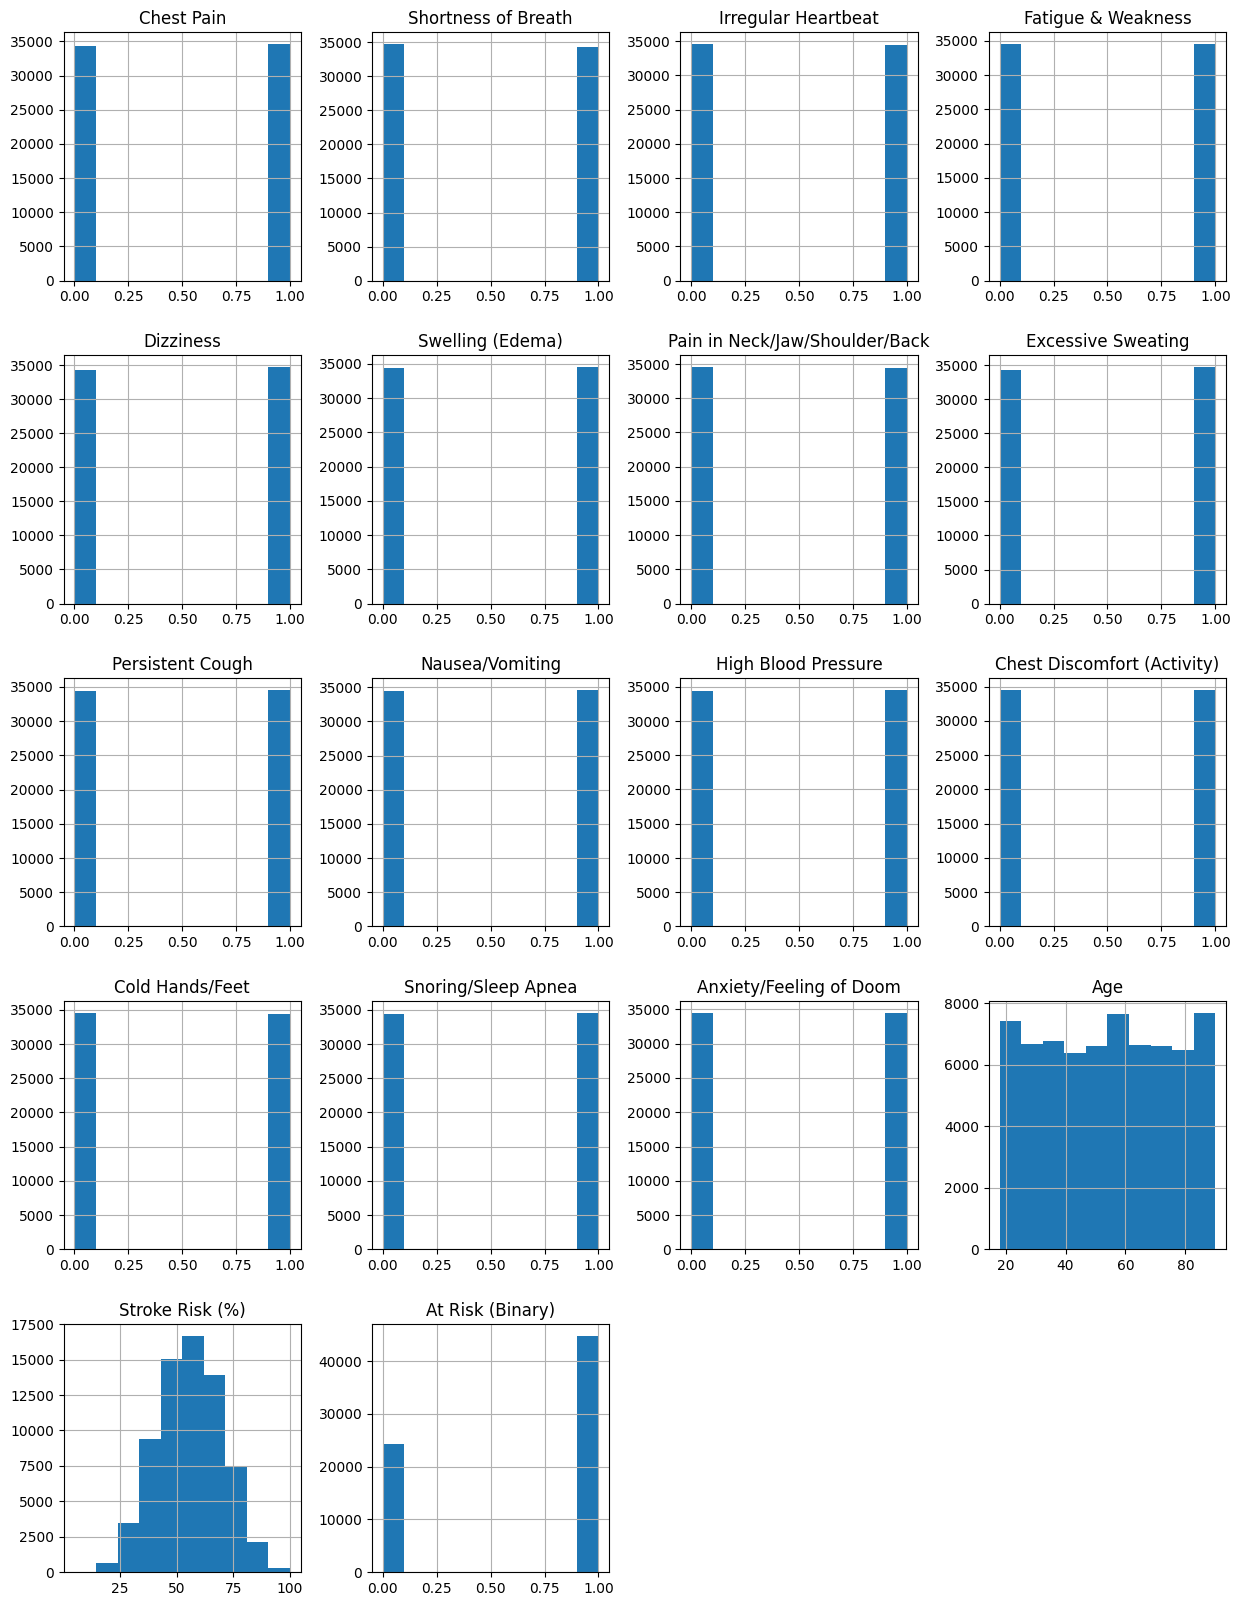

In [30]:
# Plot Histogram to See the Distribution of the Data

fig = plt.figure(figsize = (15,20))
ax = fig.gca()
df.hist(ax = ax)
plt.show()

Only Heart Disease Partipants¶

<ipython-input-31-cf51bdae04a4>:6: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  dataset_copy.hist(ax = ax)


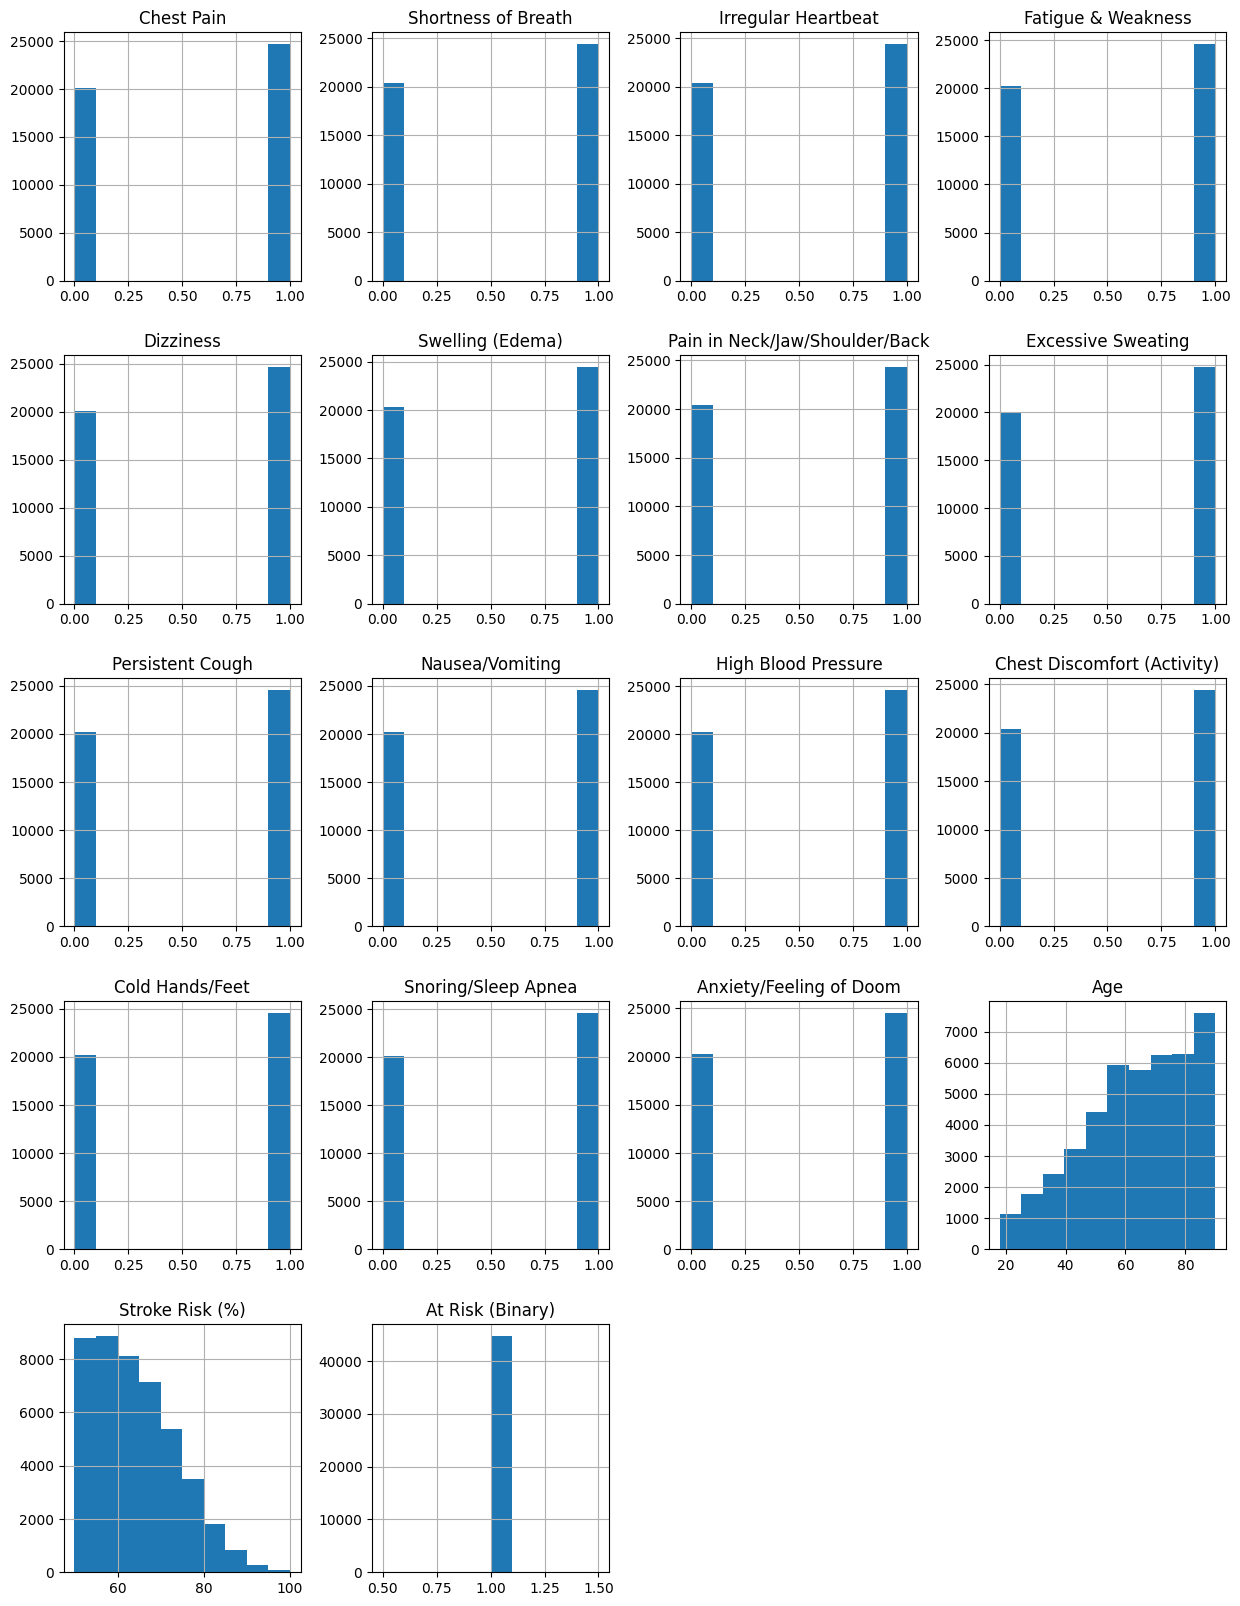

In [31]:
# Plot Histogram to See the Distribution of the Data for Heart Disease Cases
dataset_copy=df[df['At Risk (Binary)']==1]
columns=df.columns[:21]
fig = plt.figure(figsize = (15,20))
ax = fig.gca()
dataset_copy.hist(ax = ax)
plt.show()

In [32]:
def plot_histogram(df, numerical_cols):
    """Plot histograms for numerical features to visualize their distributions."""
    num_plots = len(numerical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)  
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()
    
    for i, col in enumerate(numerical_cols):
        sns.histplot(df[col], kde=False, bins=30, color='skyblue', edgecolor='black', ax=axes[i])
        axes[i].set_title(f"Histogram of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Frequency")
    
    for i in range(num_plots, len(axes)):
        axes[i].axis('off') 
    
    plt.tight_layout()
    plt.show()

In [33]:
def plot_boxplot(df, numerical_cols):
    """Plot boxplots for numerical features to visualize the distribution and detect outliers."""
    num_plots = len(numerical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten() 
    
    for i, col in enumerate(numerical_cols):
        sns.boxplot(x=df[col], color='lightgreen', ax=axes[i])
        axes[i].set_title(f"Boxplot of {col}")
        axes[i].set_xlabel(col)
    
    for i in range(num_plots, len(axes)):
        axes[i].axis('off') 
    
    plt.tight_layout()
    plt.show()

In [34]:
def plot_kde(df, numerical_cols):
    """Plot KDE (Kernel Density Estimate) for numerical features to visualize smooth distributions."""
    num_plots = len(numerical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()
    
    for i, col in enumerate(numerical_cols):
        sns.kdeplot(df[col], shade=True, color='blue', alpha=0.5, ax=axes[i])
        axes[i].set_title(f"KDE of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Density")
    
    for i in range(num_plots, len(axes)):
        axes[i].axis('off') 
    
    plt.tight_layout()
    plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


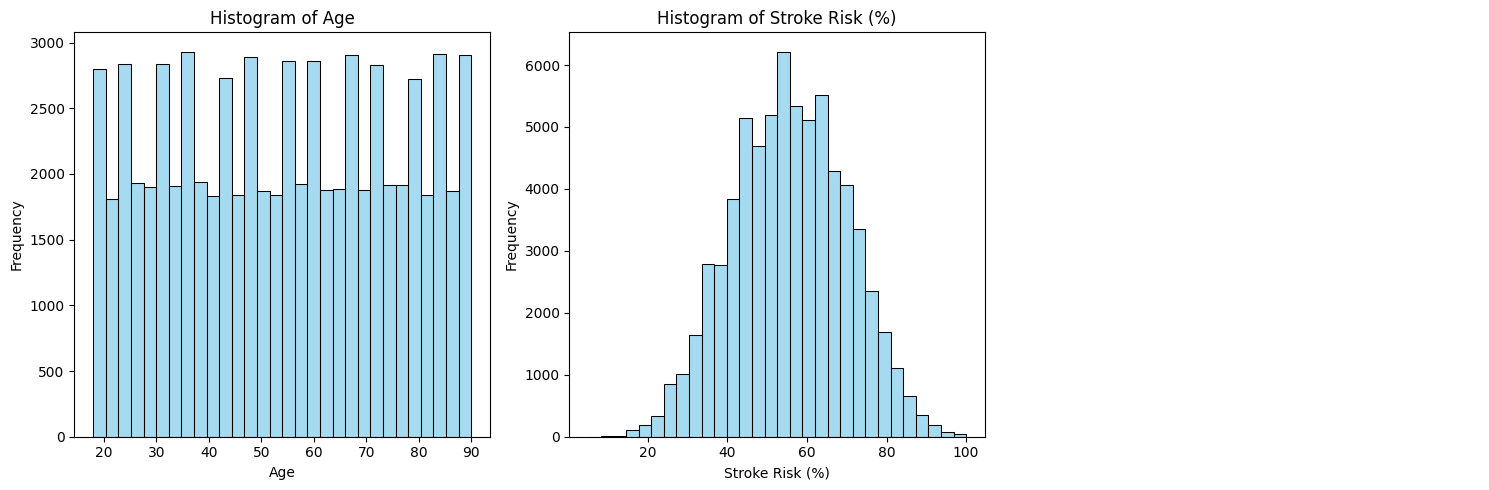

In [35]:
plot_histogram(df, filtered_classification["numerical"])

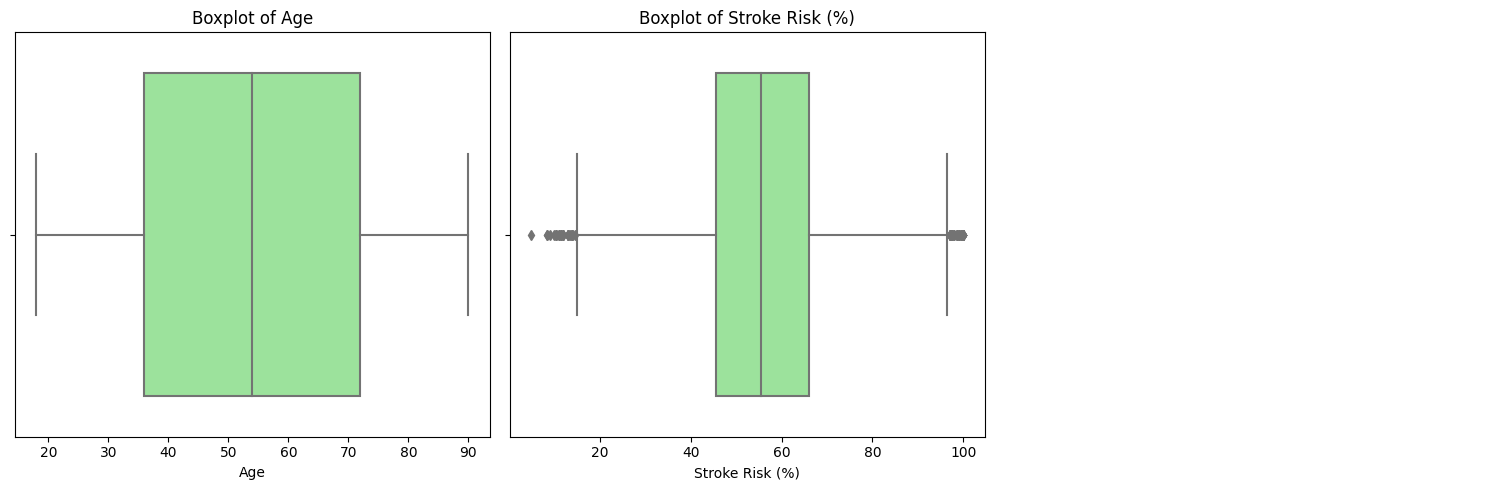

In [36]:
plot_boxplot(df, filtered_classification["numerical"])

<ipython-input-34-d2d2644a338c>:10: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[col], shade=True, color='blue', alpha=0.5, ax=axes[i])
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
<ipython-input-34-d2d2644a338c>:10: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[col], shade=True, color='blue', alpha=0.5, ax=axes[i])
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.


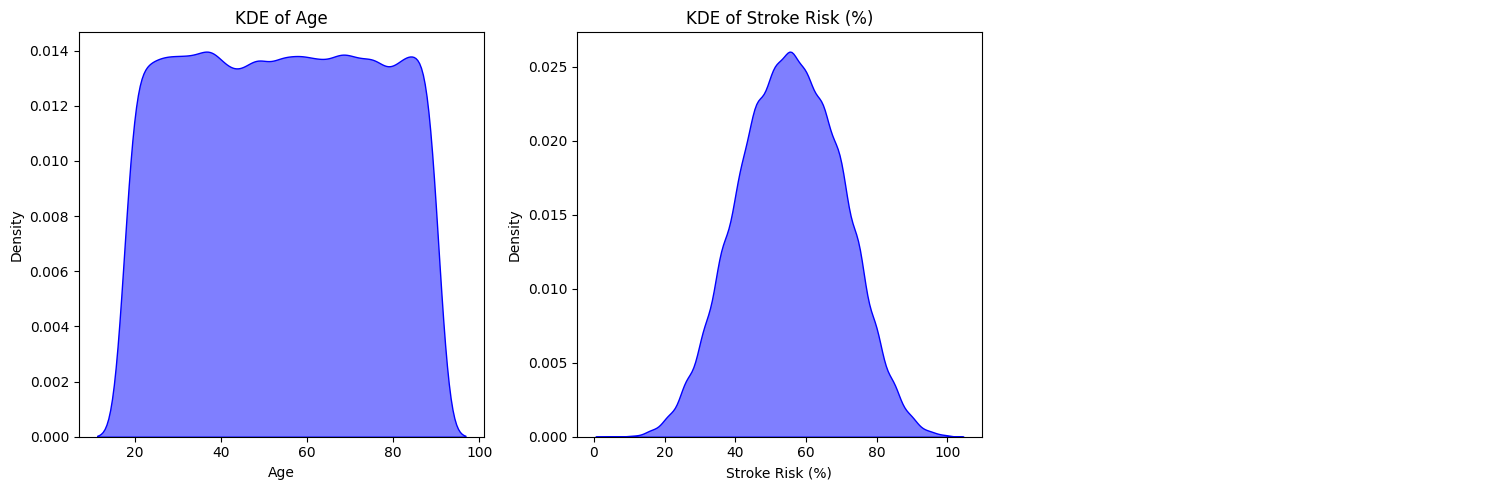

In [37]:
plot_kde(df, filtered_classification["numerical"])

In [38]:
def plot_barplot(df, categorical_cols):
    """Plot bar plots for categorical features to visualize the distribution of different categories."""
    num_plots = len(categorical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0) 
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten() 
    
    for i, col in enumerate(categorical_cols):
        sns.countplot(x=df[col], palette="Set2", ax=axes[i])
        axes[i].set_title(f"Bar Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")
    
    for i in range(num_plots, len(axes)):
        axes[i].axis('off') 
    
    plt.tight_layout()
    plt.show()

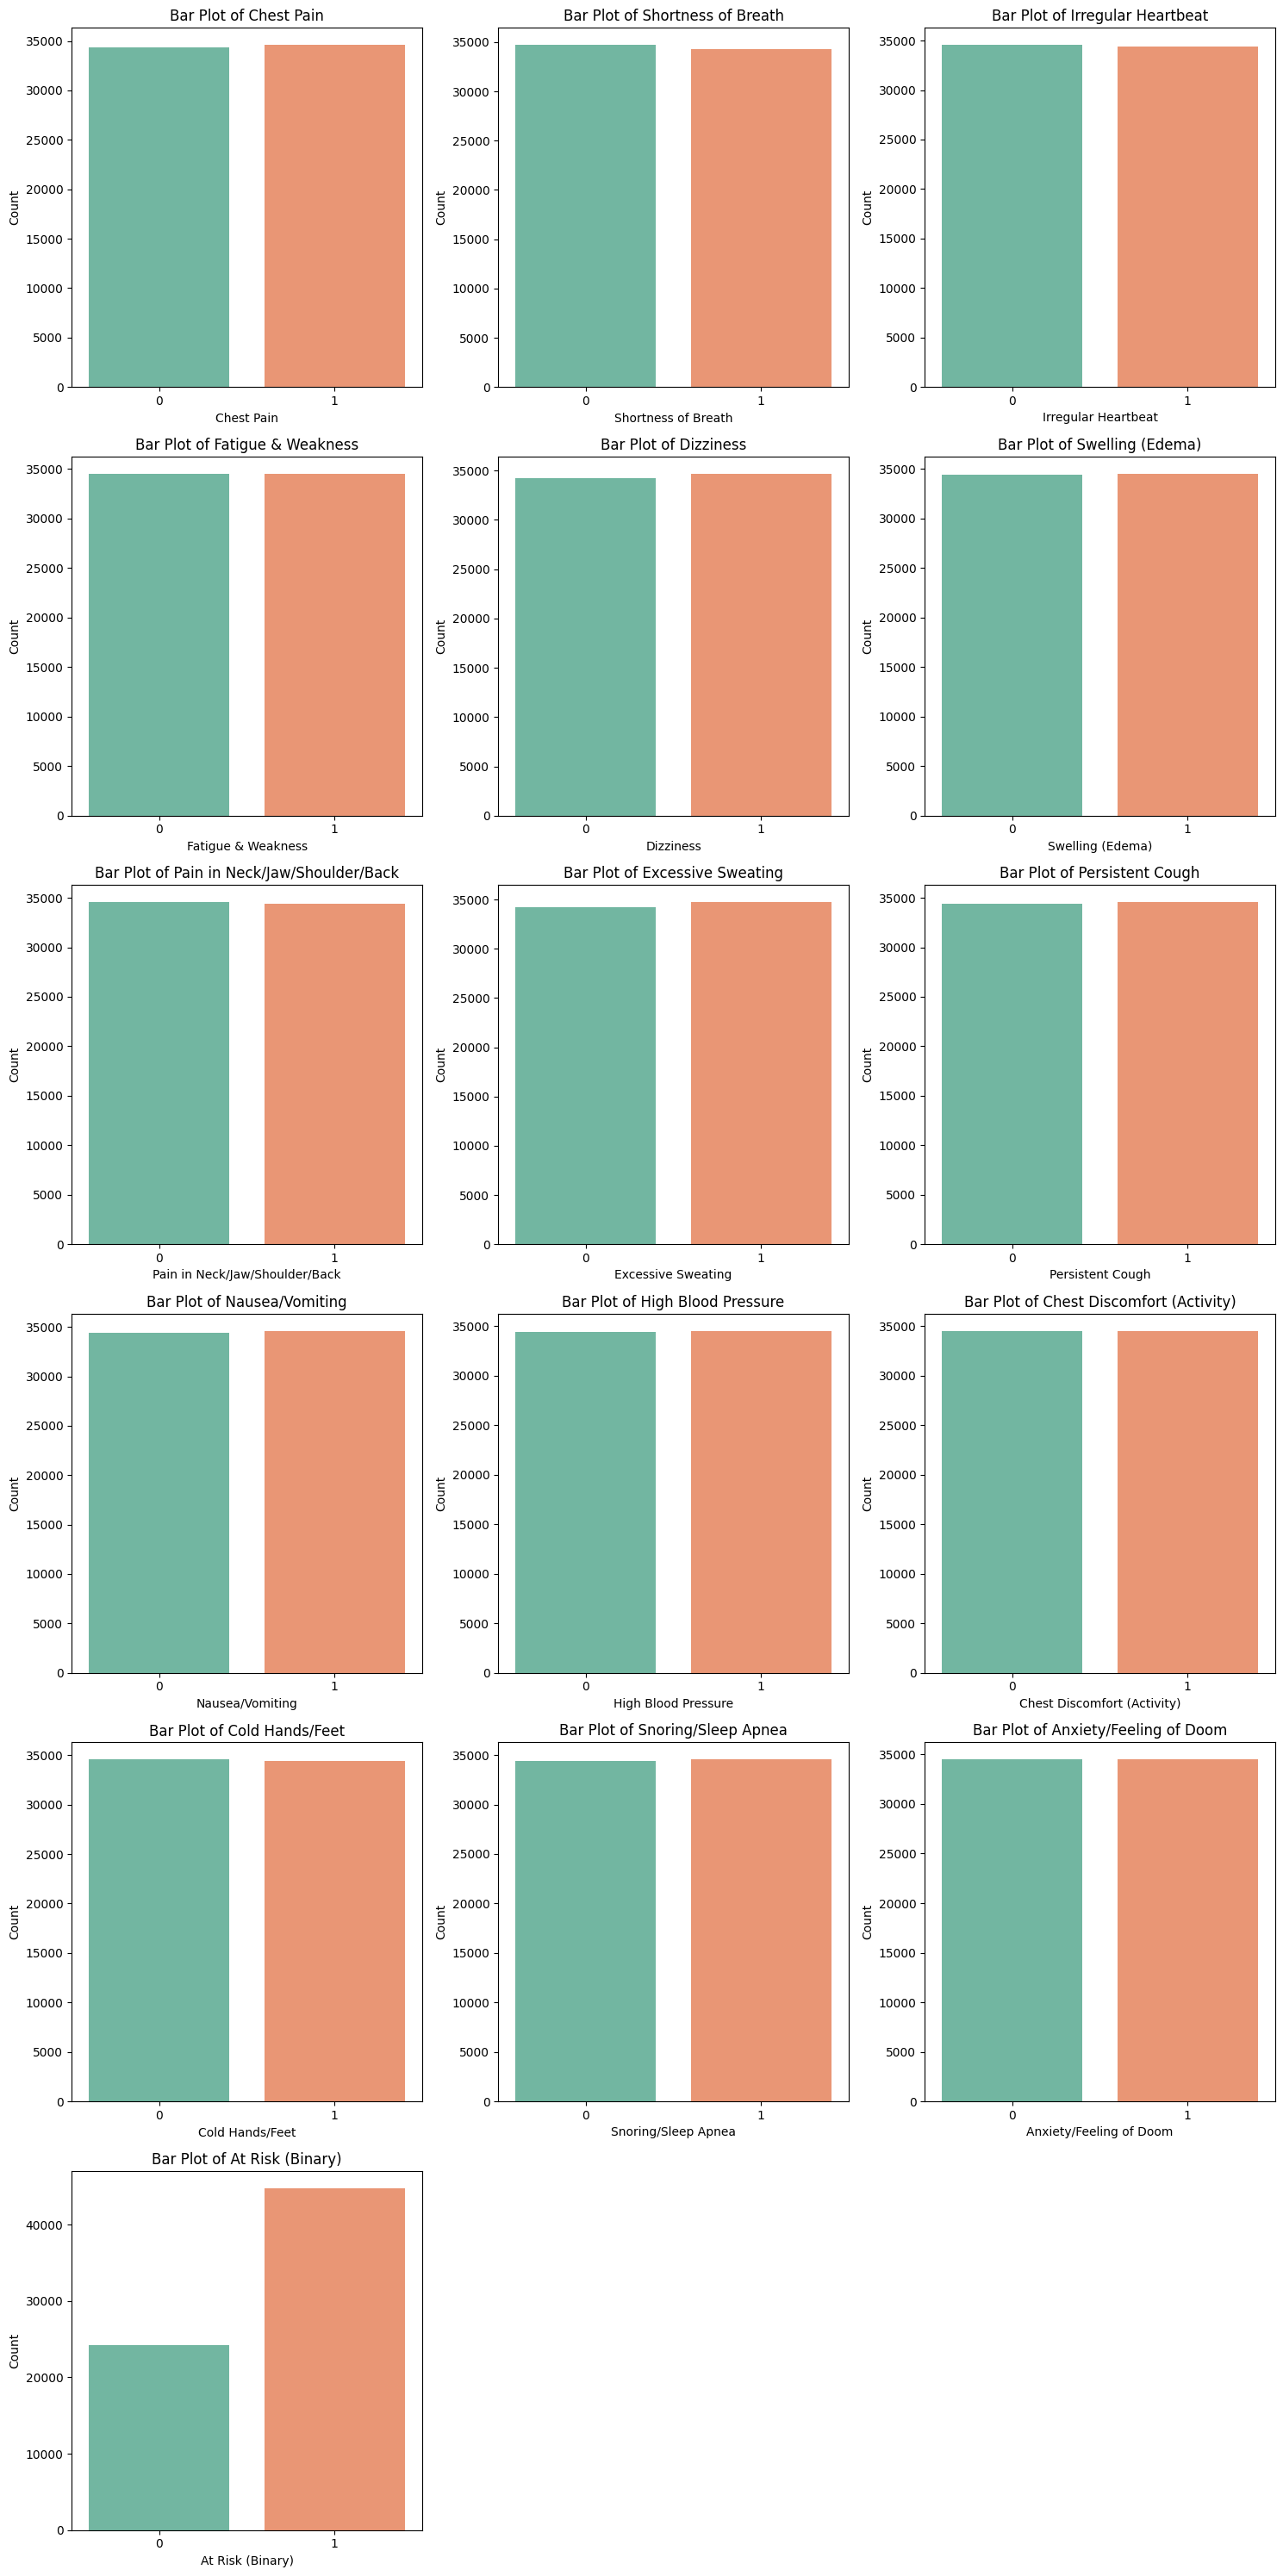

In [39]:
plot_barplot(df, filtered_classification["binary"])

In [40]:
# At Risk (Binary)
# Check for class imbalance
df['At Risk (Binary)'].value_counts()/len(df)

At Risk (Binary)
1    0.649212
0    0.350788
Name: count, dtype: float64

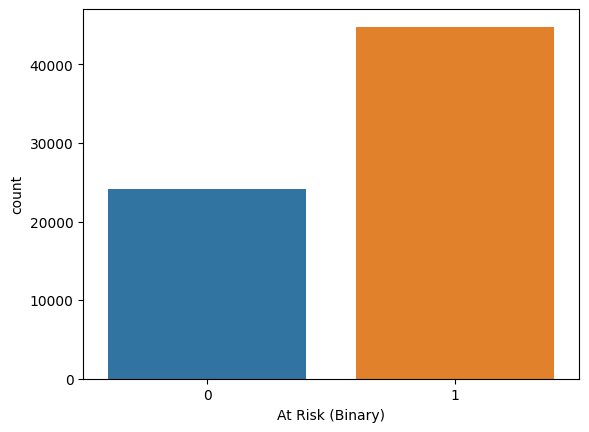

In [41]:
sns.countplot(x='At Risk (Binary)',data=df)
plt.show()

<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>5. Outlier Detection</b>
</div>

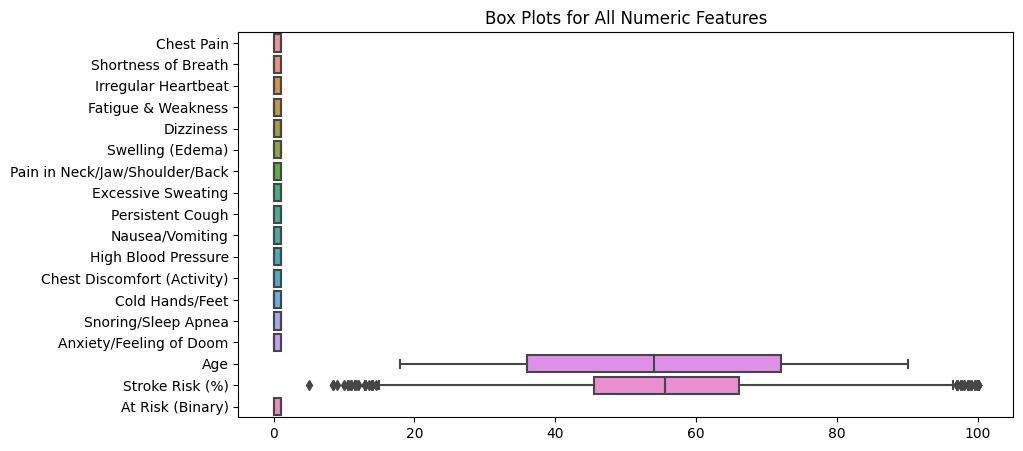

In [42]:
#Check for outliers
import seaborn as sns
import matplotlib.pyplot as plt

# Select only numeric columns (exclude categorical)
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Plot boxplots for all numeric features
plt.figure(figsize=(10, 5))  # Adjust figure size
sns.boxplot(data=df[numeric_cols], orient="h")  # Horizontal boxplots
plt.title("Box Plots for All Numeric Features")
plt.show()

In [43]:
def plot_boxplots(df, numerical_cols):
    """Plot box plots for numerical features to visualize outliers."""
    num_plots = len(numerical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()
    
    for i, col in enumerate(numerical_cols):
        sns.boxplot(x=df[col], ax=axes[i], color='lightcoral')
        axes[i].set_title(f"Boxplot of {col}")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

In [44]:
def plot_violinplots(df, numerical_cols):
    """Plot violin plots for numerical features to visualize distribution and outliers."""
    num_plots = len(numerical_cols)
    cols_per_row = 3 
    rows = (num_plots // cols_per_row) + (num_plots % cols_per_row > 0)  

    fig, axes = plt.subplots(rows, cols_per_row, figsize=(15, 5 * rows))
    axes = axes.flatten() 

    for i, col in enumerate(numerical_cols):
        sns.violinplot(x=df[col], ax=axes[i], color='teal')
        axes[i].set_title(f"Violin Plot of {col}")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

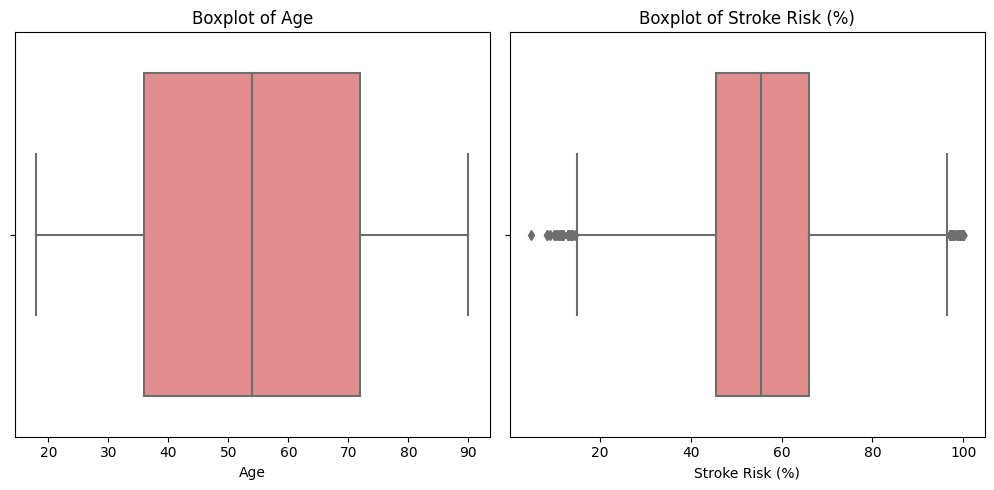

In [45]:
plot_boxplots(df, filtered_classification["numerical"])

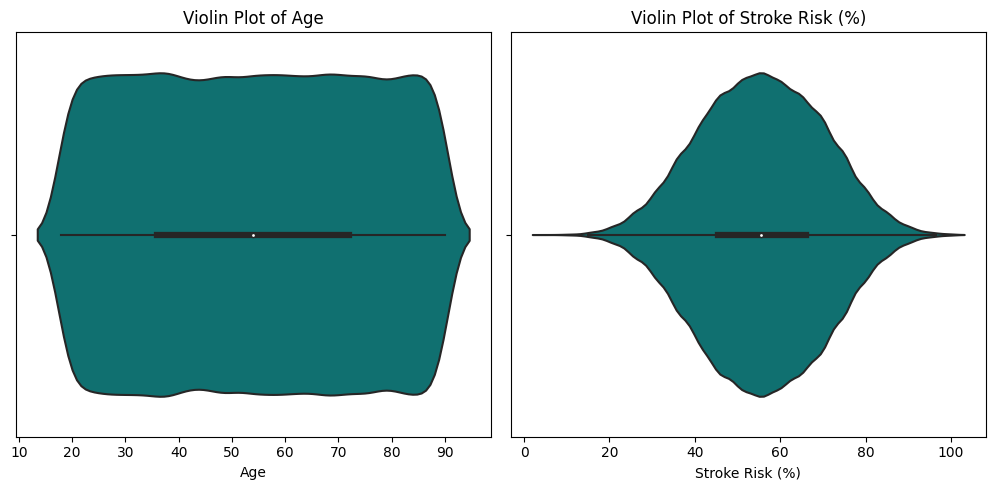

In [46]:
plot_violinplots(df, filtered_classification["numerical"])

In [47]:
def remove_outliers(df, numerical_cols, method="IQR"):
    """Remove rows containing outliers from numerical columns using IQR or Z-score."""
    df_clean = df.copy()
    
    for col in numerical_cols:
        if method == "IQR":
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
        elif method == "Z-score":
            mean = df[col].mean()
            std_dev = df[col].std()
            df_clean = df_clean[(np.abs((df[col] - mean) / std_dev) < 3)]
    
        print(f"🔹 Outliers removed in column '{col}' using {method} method.")
    
    return df_clean

In [48]:
def transform_outliers(df, numerical_cols, method="winsorize"):
    """Transform outliers in numerical columns using winsorization, log, or square root transformation."""
    df_transformed = df.copy()
    
    for col in numerical_cols:
        if method == "winsorize":
            df_transformed[col] = winsorize(df[col], limits=[0.05, 0.05])
        elif method == "log":
            df_transformed[col] = np.log1p(df[col])       
        elif method == "sqrt":
            df_transformed[col] = np.sqrt(df[col])
        
        print(f"🔹 Outliers in '{col}' transformed using {method} method.")
    
    return df_transformed

In [49]:
transform_required_columns = ["Stroke Risk (%)"]
df = transform_outliers(df, transform_required_columns)

🔹 Outliers in 'Stroke Risk (%)' transformed using winsorize method.


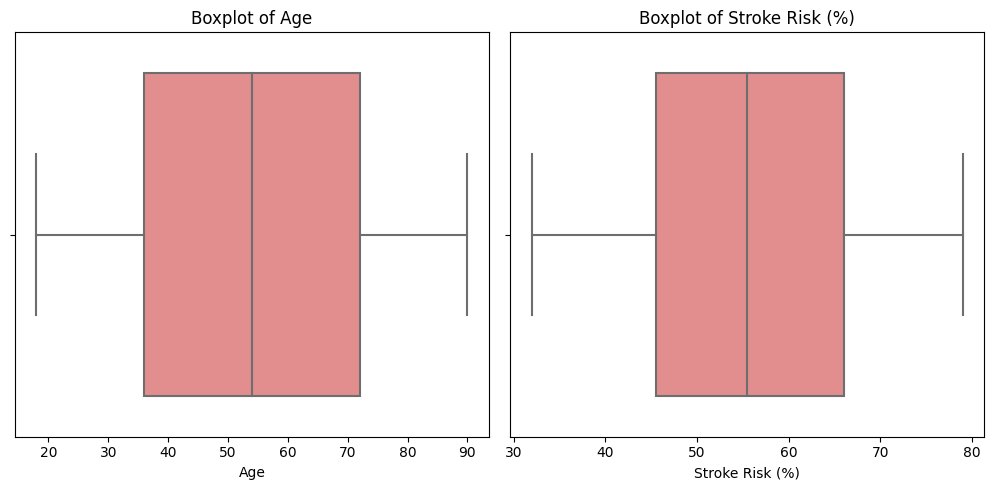

In [50]:
plot_boxplots(df, filtered_classification["numerical"])

<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>6. Correlation Analysis</b>
</div>

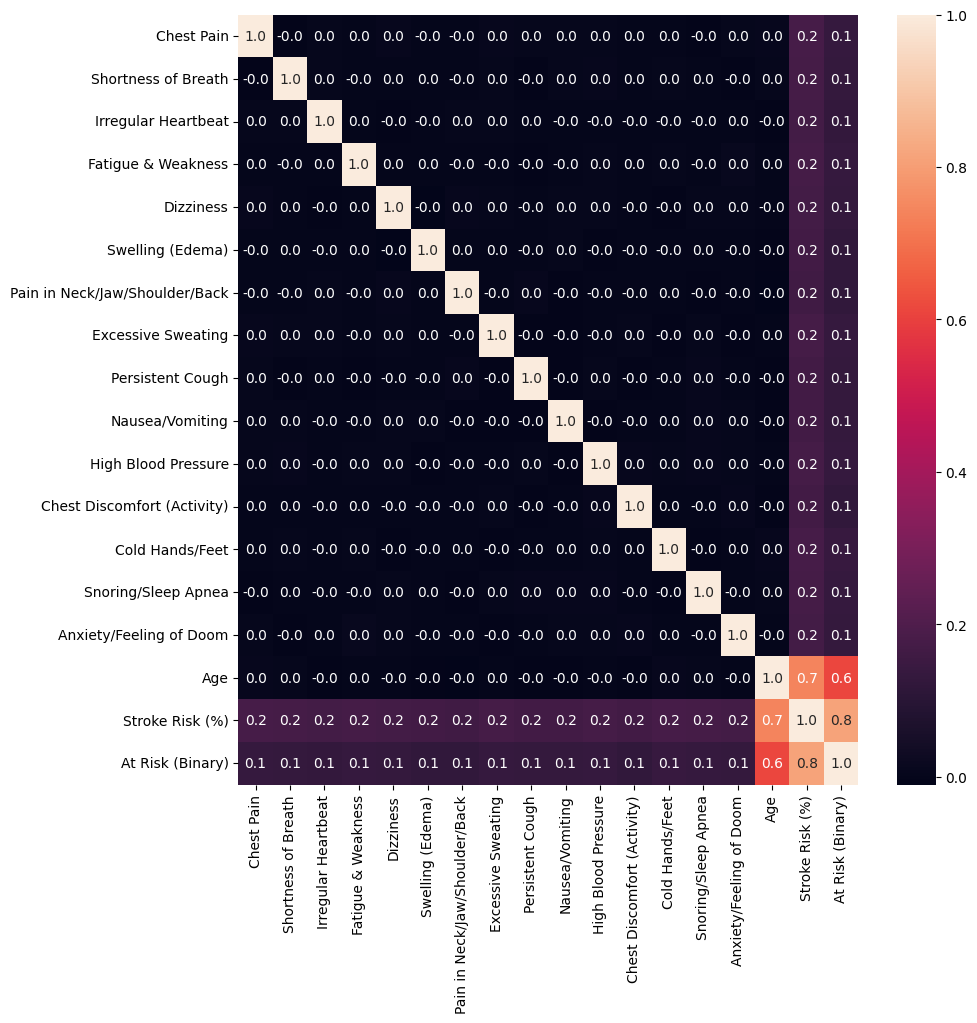

In [51]:
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(),annot=True,fmt='.1f')
plt.show()

In [52]:
def plot_correlation_heatmap(df, numerical_cols):
    """Plot a heatmap to visualize the correlation between numerical features."""
    plt.figure(figsize=(12, 6))
    correlation_matrix = df[numerical_cols].corr() 
    sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
    plt.title("🔹 Correlation Heatmap")
    plt.show()

In [53]:
def plot_pairplot(df, numerical_cols):
    """Plot pairplot for numerical columns to observe feature relationships."""
    sns.pairplot(df[numerical_cols], diag_kind="kde", corner=True)  
    plt.show()

/usr/local/lib/python3.10/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128313 (\N{SMALL BLUE DIAMOND}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


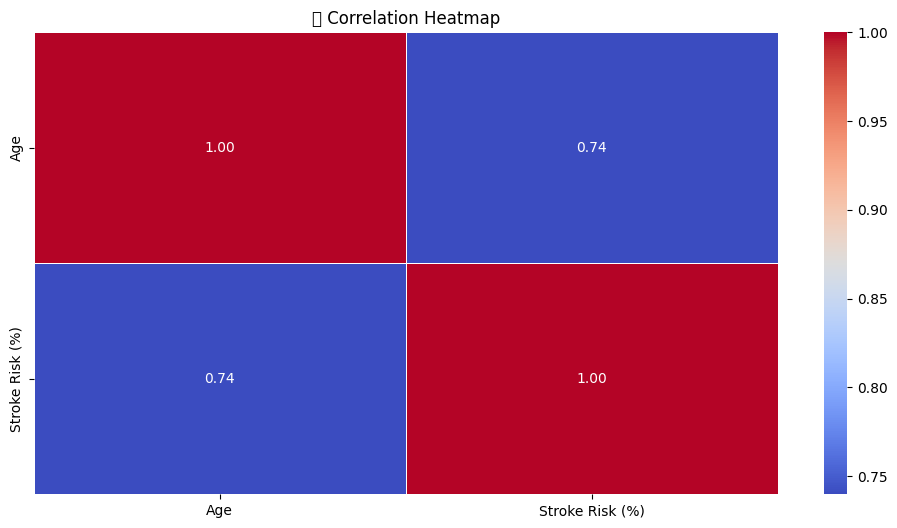

In [54]:
plot_correlation_heatmap(df, filtered_classification["numerical"])

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


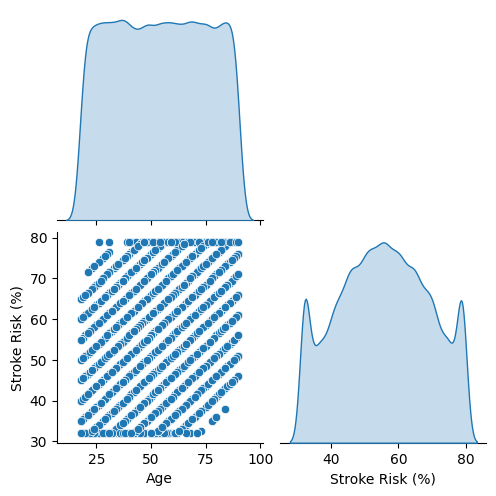

In [55]:
plot_pairplot(df, filtered_classification["numerical"])

<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>7. Train-Test Split & Sampling Strategy</b>
</div>

In [56]:
def train_test_split_custom(df, target_col, test_size=0.2, stratify=True, random_state=42):
    """Function to split data into training and testing sets."""
    X = df.drop(columns=[target_col]) 
    y = df[target_col] 

    if stratify:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, stratify=y, random_state=random_state)
    else:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)
    
    return X_train, X_test, y_train, y_test

In [57]:
X_train, X_test, y_train, y_test = train_test_split_custom(df, "At Risk (Binary)", test_size=0.1)

In [58]:
X_train

,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Age,Stroke Risk (%)
50679,0,0,0,1,1,0,0,1,1,1,0,0,0,0,1,42,42.0
11649,0,1,1,0,0,0,1,1,0,0,1,1,0,1,1,65,63.5
11161,0,0,1,1,1,0,1,1,1,1,1,1,0,0,1,82,79.0
50822,1,1,1,0,0,0,1,0,0,0,0,1,0,0,0,69,50.5
5863,0,1,0,0,1,0,0,0,1,1,1,1,0,0,1,40,46.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48954,1,1,1,1,0,0,0,1,1,1,1,1,0,1,0,42,62.0
49297,1,1,1,0,0,1,1,0,0,0,1,1,1,1,0,79,75.5
7463,1,0,1,1,0,1,1,0,1,1,1,1,0,0,1,37,59.5
46738,0,0,0,1,0,1,1,0,1,0,1,1,1,0,0,35,43.5


In [59]:
X_test

,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Age,Stroke Risk (%)
67791,0,1,0,1,0,1,1,0,1,1,1,1,0,0,0,38,50.0
54574,1,0,0,1,0,0,0,1,1,1,1,1,0,0,0,51,51.5
3678,1,0,0,1,1,1,1,1,0,1,1,0,1,0,1,19,50.5
5331,1,1,0,1,1,0,0,1,0,1,0,1,1,1,1,46,64.0
6423,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,85,79.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64988,1,1,1,0,0,0,1,0,0,0,1,1,0,1,1,21,41.5
21404,1,0,1,0,0,0,1,1,0,1,0,0,1,0,0,84,63.0
28813,1,0,1,0,0,1,1,0,1,1,1,0,1,1,0,38,55.0
9510,1,0,0,0,1,0,0,1,0,0,1,1,1,0,0,74,58.0


In [60]:
y_train

50679    0
11649    1
11161    1
50822    1
5863     0
        ..
48954    1
49297    1
7463     1
46738    0
20179    1
Name: At Risk (Binary), Length: 62081, dtype: int64

In [61]:
y_test

67791    1
54574    1
3678     1
5331     1
6423     1
        ..
64988    0
21404    1
28813    1
9510     1
12030    1
Name: At Risk (Binary), Length: 6898, dtype: int64

<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>8. Model Selection & Training</b>
</div>

In [62]:
warnings.filterwarnings("ignore")

In [63]:
def scale_data(X):
    """Scale the data using StandardScaler."""
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    return X_scaled

In [64]:
X_train = scale_data(X_train)
X_test = scale_data(X_test)

In [65]:
X_train

array([[-1.00372789, -0.99177046, -0.99895353, ...,  1.00098307,
        -0.57274557, -1.01874855],
       [-1.00372789,  1.00829782,  1.00104757, ...,  1.00098307,
         0.51782896,  0.59587626],
       [-1.00372789, -0.99177046,  1.00104757, ...,  1.00098307,
         1.32390578,  1.7599081 ],
       ...,
       [ 0.99628595, -0.99177046,  1.00104757, ...,  1.00098307,
        -0.80982699,  0.29548094],
       [-1.00372789, -0.99177046, -0.99895353, ..., -0.99901789,
        -0.90465955, -0.90610031],
       [-1.00372789, -0.99177046,  1.00104757, ..., -0.99901789,
         0.18591497, -0.04246378]])

In [66]:
X_test

array([[-0.99797248,  0.99133933, -0.99105192, ..., -1.00698292,
        -0.7570678 , -0.41825139],
       [ 1.00203164, -1.00873633, -0.99105192, ..., -1.00698292,
        -0.13489234, -0.30566073],
       [ 1.00203164, -1.00873633, -0.99105192, ...,  0.9930655 ,
        -1.66640118, -0.38072117],
       ...,
       [ 1.00203164, -1.00873633,  1.00902887, ..., -1.00698292,
        -0.7570678 , -0.0429492 ],
       [ 1.00203164, -1.00873633, -0.99105192, ..., -1.00698292,
         0.96587964,  0.18223212],
       [ 1.00203164, -1.00873633, -0.99105192, ...,  0.9930655 ,
         0.63086208,  1.04542717]])

In [67]:
def train_models(X_train, X_test, y_train, y_test):
    """Train and compare multiple classification models"""
    models = {
        "Logistic Regression": LogisticRegression(),
        "Random Forest": RandomForestClassifier(),
        "Gradient Boosting": GradientBoostingClassifier(),
        "SVM": SVC(),
        "XGBoost": XGBClassifier()
    }

    results = {}
    
    print("🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹")
    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        results[name] = acc
        print("🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹")
        print(f"{name}\nAccuracy: {acc:.4f}")
        print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}\n")
        print("🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹")
    
    print("🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹")
    
    return results

In [68]:
results = train_models(X_train, X_test, y_train, y_test)

🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
Logistic Regression
Accuracy: 1.0000
Confusion Matrix:
[[2420    0]
 [   0 4478]]

🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
Random Forest
Accuracy: 1.0000
Confusion Matrix:
[[2420    0]
 [   0 4478]]

🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
Gradient Boosting
Accuracy: 1.0000
Confusion Matrix:
[[2420    0]
 [   0 4478]]

🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
SVM
Accuracy: 0.9936
Confusion Matrix:
[[2395   25]
 [  19 4459]]

🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
XGBoost
Accuracy: 0.9858
Confusion Matrix:
[[2420    0]
 [  98 4380]]

🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹


In [69]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, mean_absolute_error, mean_squared_error)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import warnings
warnings.filterwarnings('ignore')

# 

# ✅ Define models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "Multilayer Perceptron": MLPClassifier(max_iter=500, random_state=42),
    "Naive Bayes": GaussianNB(),
    "Extra Trees": ExtraTreesClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    "LightGBM": LGBMClassifier(random_state=42),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=42)
}

# ✅ Metrics function
def evaluate_model(name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    TN, FP, FN, TP = cm.ravel()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    specificity = TN / (TN + FP)
    tpr = recall  # same as sensitivity
    fpr = FP / (FP + TN)
    csi = TP / (TP + FP + FN)  # Critical Success Index
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall (Sensitivity)": recall,
        "F1 Score": f1,
        "Specificity": specificity,
        "TPR": tpr,
        "FPR": fpr,
        "CSI": csi,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse
    }

# ✅ Train and evaluate all models
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    metrics = evaluate_model(name, y_test, y_pred)
    results.append(metrics)

# ✅ Create DataFrame of results
results_df = pd.DataFrame(results)
pd.set_option('display.max_columns', None)
print(results_df.round(4))


[LightGBM] [Info] Number of positive: 40304, number of negative: 21777
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003644 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 215
[LightGBM] [Info] Number of data points in the train set: 62081, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.649216 -> initscore=0.615596
[LightGBM] [Info] Start training from score 0.615596
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: 

In [70]:
# ✅ Convert results to DataFrame
results_df = pd.DataFrame(results)

# ✅ Multiply all metric columns (except 'Model') by 100
metric_cols = results_df.columns.drop('Model')
results_df[metric_cols] = results_df[metric_cols] * 100

# ✅ Format to 2 decimal places
results_df[metric_cols] = results_df[metric_cols].applymap(lambda x: f"{x:.2f}")

# ✅ Optional: Sort by F1 Score or any other metric
results_df = results_df.sort_values(by='F1 Score', ascending=False)

# ✅ Display full DataFrame
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
print(results_df)

                   Model Accuracy Precision Recall (Sensitivity) F1 Score  \
2                    SVM    99.36     99.44                99.58    99.51   
5            Extra Trees    99.29     99.42                99.49    99.45   
7                XGBoost    98.58    100.00                97.81    98.89   
4            Naive Bayes    96.78     98.19                96.83    97.50   
0    Logistic Regression   100.00    100.00               100.00   100.00   
1          Random Forest   100.00    100.00               100.00   100.00   
3  Multilayer Perceptron   100.00    100.00               100.00   100.00   
6      Gradient Boosting   100.00    100.00               100.00   100.00   
8               LightGBM   100.00    100.00               100.00   100.00   
9               CatBoost   100.00    100.00               100.00   100.00   

  Specificity     TPR   FPR     CSI   MAE   MSE   RMSE  
2       98.97   99.58  1.03   99.02  0.64  0.64   7.99  
5       98.93   99.49  1.07   98.91  0

In [71]:
metrics_df = pd.DataFrame(results_df)
metrics_df

,Model,Accuracy,Precision,Recall (Sensitivity),F1 Score,Specificity,TPR,FPR,CSI,MAE,MSE,RMSE
2,SVM,99.36,99.44,99.58,99.51,98.97,99.58,1.03,99.02,0.64,0.64,7.99
5,Extra Trees,99.29,99.42,99.49,99.45,98.93,99.49,1.07,98.91,0.71,0.71,8.43
7,XGBoost,98.58,100.00,97.81,98.89,100.00,97.81,0.00,97.81,1.42,1.42,11.92
4,Naive Bayes,96.78,98.19,96.83,97.50,96.69,96.83,3.31,95.13,3.22,3.22,17.94
0,Logistic Regression,100.00,100.00,100.00,100.00,100.00,100.00,0.00,100.00,0.00,0.00,0.00
1,Random Forest,100.00,100.00,100.00,100.00,100.00,100.00,0.00,100.00,0.00,0.00,0.00
3,Multilayer Perceptron,100.00,100.00,100.00,100.00,100.00,100.00,0.00,100.00,0.00,0.00,0.00
6,Gradient Boosting,100.00,100.00,100.00,100.00,100.00,100.00,0.00,100.00,0.00,0.00,0.00
8,LightGBM,100.00,100.00,100.00,100.00,100.00,100.00,0.00,100.00,0.00,0.00,0.00
9,CatBoost,100.00,100.00,100.00,100.00,100.00,100.00,0.00,100.00,0.00,0.00,0.00


**** Ensemble Learning Code (Stacking, Voting, Bagging)****

<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>9. Model Evaluation & Metrics</b>
</div>

In [ ]:
# 🔹 Best Performers: Random Forest, Gradient Boosting, and XGBoost all achieved perfect accuracy, 
#    indicating robust performance across all metrics.

# 🔹 Room for Improvement: SVM, while still achieving good accuracy, showed some misclassifications 
#    (false positives and false negatives), suggesting it might benefit from further optimization. 
#    Models like Random Forest, Gradient Boosting, and XGBoost seem to be the best choices for this dataset.

<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>10. Feature Importance</b>
</div>

In [ ]:
def plot_feature_importance(model, X, feature_names=None):
    """Plot the feature importance for tree-based models."""
    if hasattr(model, 'feature_importances_'): 
        importance = model.feature_importances_

        if feature_names is None:
            if hasattr(X, 'columns'):
                feature_names = X.columns
            else:
                feature_names = [f"Feature {i}" for i in range(X.shape[1])]
        
        indices = np.argsort(importance)[::-1]
        
        plt.figure(figsize=(10, 6))
        plt.barh(range(X.shape[1]), importance[indices], align="center")
        plt.yticks(range(X.shape[1]), [feature_names[i] for i in indices])
        plt.title("Feature Importance for Random Forest")
        plt.xlabel('Importance')
        plt.show()

In [ ]:
def feature_importance_rf(X_train, y_train, feature_names=None, random_state=42):
    """Train Random Forest model and plot feature importance."""
    rf_model = RandomForestClassifier(random_state=random_state)
    rf_model.fit(X_train, y_train)
    plot_feature_importance(rf_model, X_train, feature_names)

In [ ]:
feature_importance_rf(X_train, y_train, df.columns)

<div style="border: 10px solid black; background-color:#ffd700; color:red; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>Thank you for reading! If you found this notebook helpful, please consider giving it an upvote. Your support is appreciated! 😊</b>
</div>